# Food-101 학습 — 단계별 노트북

목표: Food-101(101개 음식 카테고리, 101,000장 이미지)로 **데이터 로딩 → 모델 구성(전이학습) → 학습 → 평가 → 추론**까지
한 셀씩 눈으로 확인하면서 진행합니다.

RTX 2060(6GB)에서 바로 돌아가도록 설계했습니다. 각 셀을 순서대로 실행하세요.


## 0. 준비: 라이브러리 설치 확인
먼저 아래 셀로 필요한 패키지가 있는지 확인합니다. 없는 게 있으면 터미널에서 설치하세요:
```bash
pip install torch torchvision matplotlib jupyter ipykernel
```

In [1]:
import torch
import torchvision
import matplotlib
print("torch", torch.__version__)
print("torchvision", torchvision.__version__)
print("cuda available:", torch.cuda.is_available())


torch 2.15.0+cu132
torchvision 0.29.2+cu132
cuda available: True


## 1. 환경 확인
GPU가 제대로 잡히는지 다시 한 번 확인합니다.

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device =", device)
if device.type == "cuda":
    print("GPU =", torch.cuda.get_device_name(0))
    print("VRAM(GB) =", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1))


device = cuda
GPU = NVIDIA GeForce RTX 2060
VRAM(GB) = 6.0


## 2. 하이퍼파라미터

- `IMG_SIZE`: 입력 이미지 크기 (작을수록 빠르고 VRAM도 적게 씀)
- `BATCH_SIZE`: 6GB VRAM 기준으로 32~64 정도가 안전
- `EPOCHS`: 전이학습이라 많지 않아도 됨 (우선 5로 시작, 결과 보고 늘리기)


In [3]:
from pathlib import Path

DATA_DIR = Path("../data").resolve()
CHECKPOINT_DIR = Path("../checkpoints").resolve()
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

IMG_SIZE = 160
BATCH_SIZE = 32
EPOCHS = 5
LR = 1e-4
NUM_WORKERS = 4

print("DATA_DIR =", DATA_DIR)
print("CHECKPOINT_DIR =", CHECKPOINT_DIR)


DATA_DIR = /home/noni/Documents/knowledge/data
CHECKPOINT_DIR = /home/noni/Documents/knowledge/checkpoints


## 3. 데이터셋 로드 (Food-101)

처음 실행하면 약 4.65GB를 다운로드합니다 (`download=True`). 시간이 좀 걸릴 수 있어요.

전이학습을 위해 ImageNet 사전학습 가중치가 기대하는 정규화(mean/std)를 그대로 사용합니다.


In [4]:
from torchvision import transforms
from torchvision.datasets import Food101

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

test_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

train_ds = Food101(root=DATA_DIR, split="train", download=True, transform=train_transform)
test_ds = Food101(root=DATA_DIR, split="test", download=True, transform=test_transform)

print("train size:", len(train_ds))
print("test size:", len(test_ds))
print("num classes:", len(train_ds.classes))
print("sample classes:", train_ds.classes[:5])


train size: 75750
test size: 25250
num classes: 101
sample classes: ['apple_pie', 'baby_back_ribs', 'baklava', 'beef_carpaccio', 'beef_tartare']


## 4. 샘플 이미지 눈으로 확인
데이터가 제대로 로드됐는지, 라벨이 맞는지 직접 확인합니다.

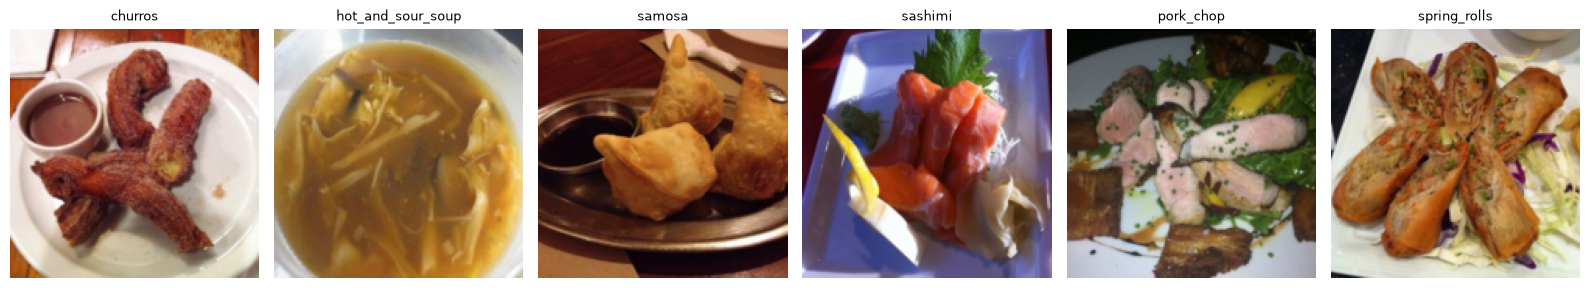

In [5]:
import matplotlib.pyplot as plt
import torch

def denormalize(img_tensor):
    mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(3, 1, 1)
    return (img_tensor * std + mean).clamp(0, 1)

fig, axes = plt.subplots(1, 6, figsize=(16, 3))
for i, ax in enumerate(axes):
    img, label = train_ds[i * 800]  # 간격을 둬서 다양한 클래스가 보이게
    img = denormalize(img).permute(1, 2, 0).numpy()
    ax.imshow(img)
    ax.set_title(train_ds.classes[label], fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()


In [6]:
torch.tensor([1, 2, 3]).view(3,1,1)

tensor([[[1]],

        [[2]],

        [[3]]])

## 5. DataLoader 구성

학습/평가용 DataLoader를 만듭니다. `num_workers`는 CPU 코어 수에 맞춰 조절하세요(너무 크면 오히려 느려질 수 있음).


In [7]:
from torch.utils.data import DataLoader

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                           num_workers=NUM_WORKERS, pin_memory=True)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=True)

print("train batches:", len(train_loader))
print("test batches:", len(test_loader))


train batches: 2368
test batches: 790


## 6. 모델 구성 — 전이학습 (ResNet-18)

101개 클래스를 scratch부터 학습하면 많은 epoch이 필요합니다. 대신 ImageNet으로 사전학습된
ResNet-18을 불러와 마지막 분류기(fc)만 101개 클래스에 맞게 바꿔서 학습합니다 (fine-tuning).

이 셀을 처음 실행하면 사전학습 가중치(약 45MB)를 추가로 다운로드합니다.


In [8]:
import torch.nn as nn
from torchvision.models import resnet18, ResNet18_Weights

NUM_CLASSES = len(train_ds.classes)

model = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)
model = model.to(device)

num_params = sum(p.numel() for p in model.parameters())
print(f"total params: {num_params:,}")


total params: 11,228,325


## 7. 손실함수 / 옵티마이저

전체 모델을 fine-tuning합니다 (freeze 없이). VRAM이 부족하면 `BATCH_SIZE`를 줄이세요.


In [9]:
import torch.nn.functional as F

optimizer = torch.optim.AdamW(model.parameters(), lr=LR)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)


## 8. 학습 루프

epoch마다 loss/accuracy를 출력하고, GPU 메모리 사용량도 같이 찍어서 6GB 안에서 잘 돌고 있는지 확인합니다.


In [10]:
import time

history = {"train_loss": [], "train_acc": []}

def train_one_epoch(epoch):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    start = time.time()

    for step, (images, labels) in enumerate(train_loader):
        images, labels = images.to(device, non_blocking=True), labels.to(device, non_blocking=True)

        optimizer.zero_grad()
        outputs = model(images)
        loss = F.cross_entropy(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += images.size(0)

        if step % 100 == 0:
            mem_gb = torch.cuda.memory_allocated() / 1e9 if device.type == "cuda" else 0
            print(f"  epoch {epoch} step {step}/{len(train_loader)}  "
                  f"loss={loss.item():.4f}  gpu_mem={mem_gb:.2f}GB")

    scheduler.step()
    elapsed = time.time() - start
    epoch_loss = running_loss / total
    epoch_acc = correct / total
    history["train_loss"].append(epoch_loss)
    history["train_acc"].append(epoch_acc)
    print(f"epoch {epoch} done in {elapsed:.1f}s  loss={epoch_loss:.4f}  acc={epoch_acc:.4f}")
    return epoch_loss, epoch_acc


In [11]:
for epoch in range(1, EPOCHS + 1):
    train_one_epoch(epoch)

    checkpoint_path = CHECKPOINT_DIR / f"food101_resnet18_epoch{epoch}.pt"
    torch.save({
        "model_state": model.state_dict(),
        "optimizer_state": optimizer.state_dict(),
        "epoch": epoch,
        "classes": train_ds.classes,
    }, checkpoint_path)
    print(f"checkpoint saved: {checkpoint_path}")


0.00s - Debugger warning: It seems that frozen modules are being used, which may
0.00s - make the debugger miss breakpoints. Please pass -Xfrozen_modules=off
0.00s - to python to disable frozen modules.
0.00s - Note: Debugging will proceed. Set PYDEVD_DISABLE_FILE_VALIDATION=1 to disable this validation.
0.00s - Debugger warning: It seems that frozen modules are being used, which may
0.00s - make the debugger miss breakpoints. Please pass -Xfrozen_modules=off
0.00s - to python to disable frozen modules.
0.00s - Note: Debugging will proceed. Set PYDEVD_DISABLE_FILE_VALIDATION=1 to disable this validation.


  epoch 1 step 0/2368  loss=4.9329  gpu_mem=0.19GB
  epoch 1 step 100/2368  loss=3.6687  gpu_mem=0.19GB
  epoch 1 step 200/2368  loss=3.2168  gpu_mem=0.19GB
  epoch 1 step 300/2368  loss=2.3738  gpu_mem=0.19GB
  epoch 1 step 400/2368  loss=2.8072  gpu_mem=0.19GB
  epoch 1 step 500/2368  loss=2.1891  gpu_mem=0.19GB
  epoch 1 step 600/2368  loss=2.1312  gpu_mem=0.19GB
  epoch 1 step 700/2368  loss=1.8058  gpu_mem=0.19GB
  epoch 1 step 800/2368  loss=2.1562  gpu_mem=0.19GB
  epoch 1 step 900/2368  loss=2.0193  gpu_mem=0.19GB
  epoch 1 step 1000/2368  loss=1.9355  gpu_mem=0.19GB
  epoch 1 step 1100/2368  loss=2.1243  gpu_mem=0.19GB
  epoch 1 step 1200/2368  loss=1.8762  gpu_mem=0.19GB
  epoch 1 step 1300/2368  loss=1.8970  gpu_mem=0.19GB
  epoch 1 step 1400/2368  loss=2.0070  gpu_mem=0.19GB
  epoch 1 step 1500/2368  loss=2.4119  gpu_mem=0.19GB
  epoch 1 step 1600/2368  loss=1.3792  gpu_mem=0.19GB
  epoch 1 step 1700/2368  loss=1.9642  gpu_mem=0.19GB
  epoch 1 step 1800/2368  loss=2.0516  g

## 9. 학습 곡선 확인
loss/accuracy가 epoch마다 어떻게 바뀌었는지 그려봅니다.

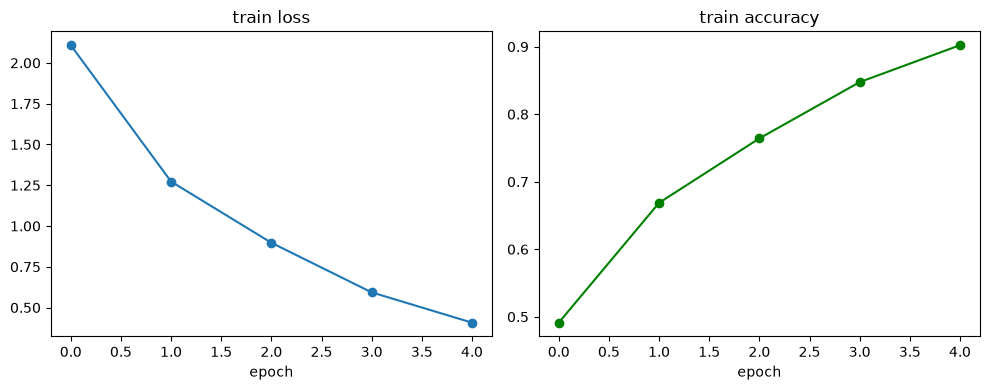

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(history["train_loss"], marker="o")
axes[0].set_title("train loss")
axes[0].set_xlabel("epoch")

axes[1].plot(history["train_acc"], marker="o", color="green")
axes[1].set_title("train accuracy")
axes[1].set_xlabel("epoch")
plt.tight_layout()
plt.show()


## 10. 테스트셋 평가
학습에 쓰지 않은 test split으로 실제 성능을 확인합니다.

In [13]:
@torch.no_grad()
def evaluate():
    model.eval()
    correct, total = 0, 0
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += images.size(0)
    return correct / total

test_acc = evaluate()
print(f"test accuracy: {test_acc:.4f}")


test accuracy: 0.7493


## 11. 샘플 추론 — 눈으로 결과 확인
테스트셋에서 몇 장 뽑아 예측 vs 실제 라벨을 비교합니다.

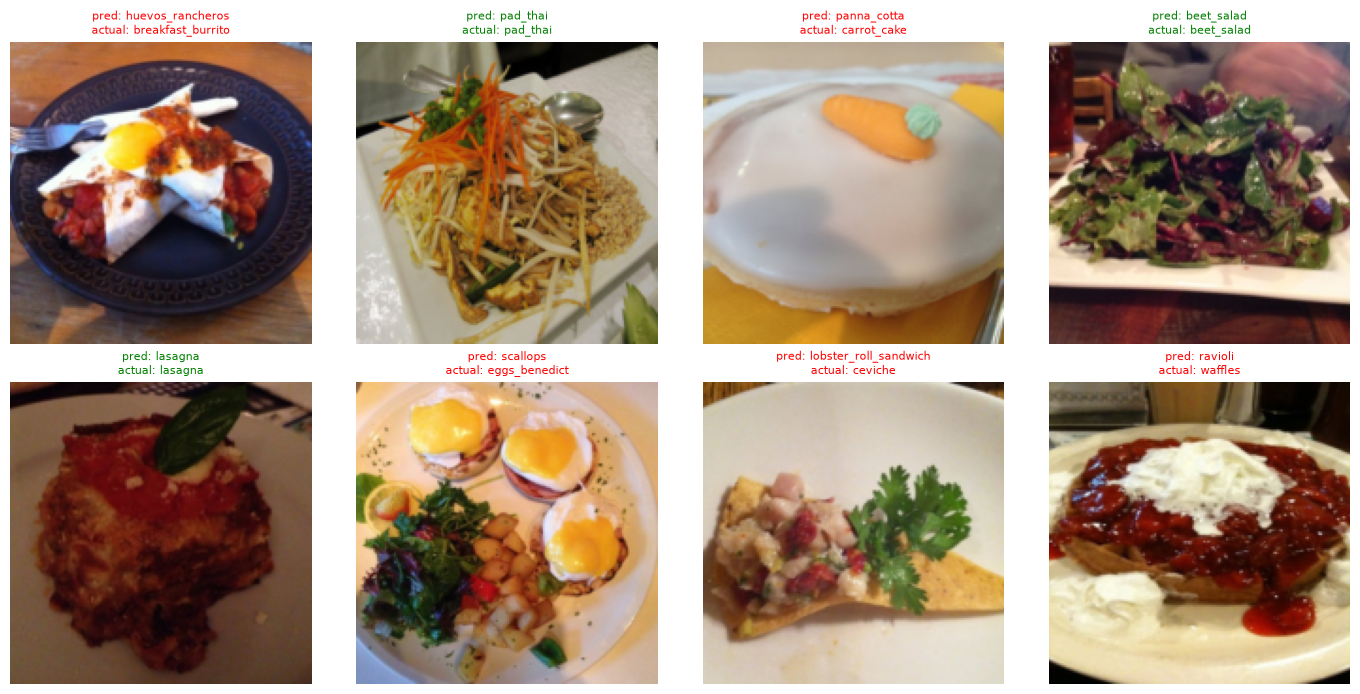

In [14]:
import random

model.eval()
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
indices = random.sample(range(len(test_ds)), 8)

with torch.no_grad():
    for ax, idx in zip(axes.flat, indices):
        img, label = test_ds[idx]
        pred = model(img.unsqueeze(0).to(device)).argmax(1).item()

        shown = denormalize(img).permute(1, 2, 0).numpy()
        ax.imshow(shown)
        correct = pred == label
        ax.set_title(
            f"pred: {train_ds.classes[pred]}\nactual: {train_ds.classes[label]}",
            fontsize=8, color="green" if correct else "red"
        )
        ax.axis("off")

plt.tight_layout()
plt.show()


## 다음에 해볼 것

- `EPOCHS`를 늘려서 정확도 변화 관찰 (지금은 5 epoch만)
- 마지막 fc만 학습하는 freeze 방식과 전체 fine-tuning 비교
- 클래스별 정확도(confusion matrix)로 어떤 음식이 잘 헷갈리는지 분석
- MLflow로 실험(하이퍼파라미터 + 결과) 기록해서 비교 가능하게 만들기
- 다음 단계인 YouCook2(시퀀스 데이터)로 넘어가기
